# 单股票：五模型探索与验证结果对比

本 Notebook 读取已经完成的实验并展示。

1. 在第一个代码单元格中填写 `RUN_NAME = "实际实验目录名"`，目录必须位于项目 `artifacts/` 下；必须加引号，不能填写 `None` 或空字符串。
2. 选择 EE6008 内核，从头运行。股票代码、数据路径、日期范围、窗口和模型参数全部来自所选目录的 `config.json`。
3. 文件名中的股票名称仅用于整理；任意一本都可以展示其他股票。切换结果只需更改 `RUN_NAME`，无需修改股票常量、图例或当前训练配置。

默认要求实验包含五个模型；查看部分模型时，将 `REQUIRE_ALL_MODELS` 改为 `False`。修改目录名后请从头运行，已有输出不会自动更新。本 Notebook 只展示验证集实验，测试期和保留期不参与评价。


In [ ]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# 从当前位置向上定位项目根目录，不依赖任何股票专用配置文件。
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "main.py").is_file() and (p / "src/data.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project or notebooks directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import importlib
import src.data as data_module
from src.evaluate import evaluate

MODELS = ("xgboost", "lightgbm", "patchtst", "lstm", "gru")
BASELINES = ("zero_return", "historical_mean", "last_return")
LABELS = {"xgboost": "XGBoost", "lightgbm": "LightGBM", "patchtst": "PatchTST",
          "lstm": "LSTM", "gru": "GRU", "zero_return": "Zero return",
          "historical_mean": "Historical mean", "last_return": "Last return"}
# 必填：只写 artifacts/ 下已有的实验目录名，并加英文引号。
# 股票代码、数据路径及实验参数由该目录的 config.json 自动提供。
# 禁止使用 None 或空字符串；不会自动选取其他实验。
RUN_NAME = "aapl_compare_all_02"

# True：要求包含五个模型；False：允许查看指定目录中的部分模型。
# 所有模型来自同一次实验，不从多个目录拼接。
REQUIRE_ALL_MODELS = True

# 仅控制局部预测图展示最后多少个验证日；不改变模型的 60 日输入窗口。
# 所有指标仍用完整验证集计算，不是仅用这里的 80 天。
RECENT_DAYS = 80

# 默认只读取结果文件；设为 True 才额外加载已保存的树模型，展示特征重要性。
# 即使启用也不会重新训练模型。
SHOW_TREE_IMPORTANCE = False

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Python:", sys.executable)

Python: f:\Enviornment\miniforge3\envs\EE6008\python.exe


## 1. 读取指定实验并核对数据

```text
RUN_NAME = "实际实验目录名"
    → artifacts/该目录/
    → config.json 决定股票、数据路径、日期、窗口和模型参数
    → predictions.csv 提供真实收益和各模型预测
    → 核对数据与指标，展示对比表及图表
```

这里没有自动扫描或回退逻辑。目录不存在、结果未完成、必要文件缺失、或不符合模型要求时直接报错，不会换成另一次实验。

| 文件 | 用途 |
|---|---|
| `config.json` | 实验配置快照；`ticker` 用于股票名称，`data_path` 用于定位原始数据 |
| `manifest.json` | 运行状态、评价分区、数据指纹及环境记录 |
| `predictions.csv` | 每个验证目标日的真实收益和模型预测 |
| `metrics.json` | 与根据逐日预测重新计算的指标核对 |
| `training.json` | 学习曲线、最佳轮次、设备及耗时 |
| `preprocessing.json` | 特征顺序、窗口及训练期标准化参数 |
| `direction_reference.json` | 多数方向基线的验证准确率 |

Notebook 不读取 `configs/` 中当前的训练配置，也不根据文件名或目录名推断股票。它会根据实验快照读取原始 CSV，并复用公共代码重建数据集以核对日期、标签和标准化参数；不会重新训练或生成预测。

原始数据文件必须仍可通过快照中的项目相对路径访问，且指纹一致。新增股票只要遵循当前公共数据格式和实验输出约定，就可以用同一逻辑展示。改变特征定义或预测任务时，还需同步公共数据与评价代码。


In [2]:
def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))


# 必须显式指定 artifacts/ 下的一个目录名；不扫描、不自动选择、不回退。
if not isinstance(RUN_NAME, str) or not RUN_NAME.strip():
    raise ValueError('请设置 RUN_NAME = "实际实验目录名"；不能使用 None 或空字符串')
if Path(RUN_NAME).name != RUN_NAME or RUN_NAME in (".", ".."):
    raise ValueError("RUN_NAME 只填写 artifacts/ 下的目录名，不填写路径")
run_dir = ROOT / "artifacts" / RUN_NAME
if not run_dir.is_dir():
    raise FileNotFoundError(f"实验目录不存在：{run_dir}")
required_files = ("manifest.json", "config.json", "metrics.json", "training.json",
                  "preprocessing.json", "direction_reference.json", "predictions.csv")
missing_files = [name for name in required_files if not (run_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"实验 {RUN_NAME} 缺少文件：{', '.join(missing_files)}")

# 股票名称和数据位置以实验快照为准，不依赖 Notebook 名称或当前训练配置。
manifest = read_json(run_dir / "manifest.json")
config = read_json(run_dir / "config.json")
ticker = config.get("ticker")
if not isinstance(ticker, str) or not ticker.strip():
    raise ValueError("实验 config.json 必须包含非空的 ticker 股票代码")
if not isinstance(config.get("data_path"), str) or not config["data_path"].strip():
    raise ValueError("实验 config.json 必须包含非空的 data_path 数据路径")
if (manifest.get("status") != "complete" or manifest.get("evaluation_split") != "validation"
        or manifest.get("test_evaluated", False) or manifest.get("holdout_evaluated", False)):
    raise ValueError("请选择已完成、且未评价测试期或保留期的验证实验")
saved_metrics = read_json(run_dir / "metrics.json")
missing_models = [name for name in MODELS if name not in saved_metrics]
if REQUIRE_ALL_MODELS and missing_models:
    raise ValueError(f"本次实验缺少模型：{', '.join(missing_models)}；查看部分模型请设置 REQUIRE_ALL_MODELS = False")
training = read_json(run_dir / "training.json")
preprocessing = read_json(run_dir / "preprocessing.json")
reference = read_json(run_dir / "direction_reference.json")
display(Markdown(f"# {ticker}：五模型探索与验证结果对比"))
print("Experiment:", run_dir)
print("Data:", config["data_path"])

# 核对当前原始 CSV 是否与训练时相同；不是重新下载数据。
current_hash = hashlib.sha256((ROOT / config["data_path"]).read_bytes()).hexdigest()
if current_hash != manifest["data_sha256"]:
    raise ValueError("Raw data differs from this experiment; restore the matching data version")
# 重建数据集只用于探索和一致性核对，不会调用任何模型训练函数。
# Refresh local code even when this kernel was started before a code update.
# Reject a module from another checkout instead of silently using its dataset rules.
if Path(data_module.__file__).resolve() != (ROOT / "src/data.py").resolve():
    raise RuntimeError("src.data was imported from another project. Restart the kernel and Run All.")
importlib.invalidate_caches()
data_module = importlib.reload(data_module)
dataset = data_module.load_dataset(config, ROOT)
# Read the feature selection from this run; older snapshots default to all eight.
features = dataset.features
print("Nasdaq features:", config.get("nasdaq_features", "all"))
print("Input features:", features)
if preprocessing["features"] != features or preprocessing["window"] != config["window"]:
    raise ValueError("Feature order or historical window does not match")
np.testing.assert_allclose(dataset.feature_mean, preprocessing["feature_mean"], rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(dataset.feature_scale, preprocessing["feature_scale"], rtol=1e-10, atol=1e-12)
np.testing.assert_allclose([dataset.target_mean, dataset.target_scale],
                          [preprocessing["target_mean"], preprocessing["target_scale"]], rtol=1e-10)

# 真正用于对比的模型预测来自已保存的 CSV，不是在 Notebook 里重新预测。
predictions = pd.read_csv(run_dir / "predictions.csv",
                          parse_dates=["window_start", "signal_date", "target_date"])
if predictions.target_date.duplicated().any() or not predictions.target_date.is_monotonic_increasing:
    raise ValueError("Prediction target dates must be unique and chronological")
for column in ("window_start", "signal_date", "target_date"):
    np.testing.assert_array_equal(predictions[column].to_numpy(), dataset.validation.dates[column].to_numpy())
np.testing.assert_allclose(predictions.actual_return, dataset.validation.y, rtol=0, atol=1e-12)
np.testing.assert_array_equal(predictions.actual_direction, (dataset.validation.y > 0).astype(int))
learned = [name for name in MODELS if name in saved_metrics]
names = [*BASELINES, *learned]
# 用完整验证集的真实值和已保存预测重算指标，再与 metrics.json 核对。
# 这是评价计算，不是重新训练；RECENT_DAYS 不会参与此处计算。
metrics = {}
for name in names:
    if name not in predictions or name not in saved_metrics:
        raise ValueError(f"Missing prediction or metrics for {name}")
    metrics[name] = evaluate(predictions.actual_return.to_numpy(), predictions[name].to_numpy())
    for key, value in metrics[name].items():
        saved = saved_metrics[name][key]
        if value is None or saved is None:
            if value != saved:
                raise ValueError(f"{name}: inconsistent metric {key}")
        else:
            np.testing.assert_allclose(value, saved, rtol=1e-8, atol=1e-12,
                                       err_msg=f"{name}: {key} disagrees with predictions")
print("Run:", run_dir.name, "| Ticker:", config["ticker"], "| Seed:", config["seed"])
print("Data:", config["data_path"])
print("Models:", ", ".join(LABELS[n] for n in learned) or "Baselines only")
print("Validation only; no training is performed here.")

# AAPL：五模型探索与验证结果对比

Experiment: f:\Singapore_study\EE6008\stock_prediction\artifacts\aapl_compare_all_01
Data: data/AAPL_Apple_stock_data.csv
Nasdaq features: all
Input features: ['return', 'vol_change', 'intraday_return', 'range', 'nasdaq_return', 'nasdaq_vol_change', 'nasdaq_intraday_return', 'nasdaq_range']
Run: aapl_compare_all_01 | Ticker: AAPL | Seed: 42
Data: data/AAPL_Apple_stock_data.csv
Models: XGBoost, LightGBM, PatchTST, LSTM, GRU
Validation only; no training is performed here.


In [3]:
display(pd.DataFrame([
    {"Split": "Train", "Samples": len(dataset.train.y),
     "First target": dataset.audit["train_target_first"], "Last target": dataset.audit["train_target_last"]},
    {"Split": "Validation", "Samples": len(dataset.validation.y),
     "First target": dataset.audit["validation_target_first"], "Last target": dataset.audit["validation_target_last"]},
]).set_index("Split"))
print("Train / validation shapes:", dataset.train.X.shape, dataset.validation.X.shape)
display(dataset.validation.dates.head())

,Samples,First target,Last target
Split,,,
Train,2960,2010-04-01,2021-12-31
Validation,501,2022-01-03,2023-12-29


Train / validation shapes: (2960, 60, 8) (501, 60, 8)


,window_start,signal_date,target_date
0,2021-10-07,2021-12-31,2022-01-03
1,2021-10-08,2022-01-03,2022-01-04
2,2021-10-11,2022-01-04,2022-01-05
3,2021-10-12,2022-01-05,2022-01-06
4,2021-10-13,2022-01-06,2022-01-07


## 2. 历史特征与五模型参数

树模型按时间顺序将 `[window, 特征数]` 展平：60 日八特征为 480 个输入，精简 Nasdaq 后六特征为 360 个输入；序列模型保留三维输入。所有模型复用共同窗口和标签。下列参数取自本次实验的配置快照。

,date,return,vol_change,intraday_return,range,nasdaq_return,nasdaq_vol_change,nasdaq_intraday_return,nasdaq_range
0,2010-01-04,NaN,NaN,0.002718,0.009906,NaN,NaN,0.006106,0.007252
1,2010-01-05,0.001729,0.219098,-0.001025,0.010915,0.000126,0.225994,0.000624,0.007844
2,2010-01-06,-0.015906,-0.082646,-0.015906,0.021235,-0.003300,-0.048364,-0.002869,0.007992
3,2010-01-07,-0.001849,-0.135882,-0.005525,0.014009,-0.000452,0.007416,0.000853,0.006991
4,2010-01-08,0.006648,-0.061871,0.007989,0.013869,0.007443,-0.054915,0.010876,0.011648
5,2010-01-11,-0.008821,0.032660,-0.012641,0.021655,-0.002054,-0.031463,-0.005321,0.010409


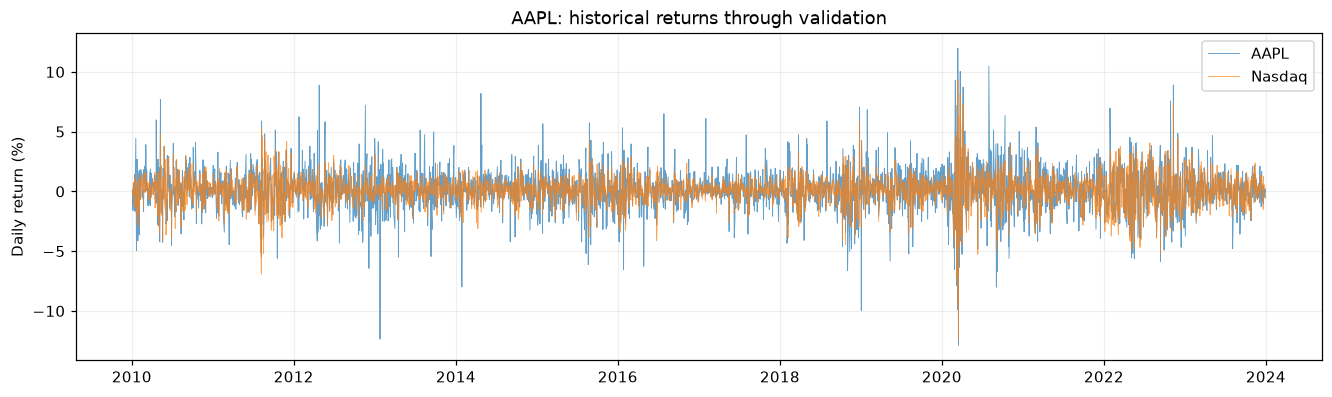

### XGBoost

,Setting
n_estimators,400
max_depth,3
learning_rate,0.03
min_child_weight,10
subsample,0.8
colsample_bytree,0.8
reg_lambda,10.0
early_stopping_rounds,30
n_jobs,4
device,cpu


### LightGBM

,Setting
n_estimators,500.00
learning_rate,0.03
num_leaves,15.00
max_depth,4.00
min_child_samples,50.00
subsample,0.80
subsample_freq,1.00
colsample_bytree,0.80
reg_lambda,10.00
reg_alpha,0.00


### PatchTST

,Setting
patch_len,12
stride,6
d_model,32
n_heads,4
n_layers,2
d_ff,64
dropout,0.2
learning_rate,0.0003
weight_decay,0.01
batch_size,64


### LSTM

,Setting
hidden_size,64
num_layers,2
dropout,0.2
learning_rate,0.0005
weight_decay,0.0001
batch_size,64
epochs,50
patience,8
device,auto


### GRU

,Setting
hidden_size,64
num_layers,2
dropout,0.2
learning_rate,0.0003
weight_decay,0.01
batch_size,64
epochs,30
patience,6
device,auto


In [4]:
display(dataset.feature_frame.head(6))
history = dataset.feature_frame.set_index("date")
fig, ax = plt.subplots(figsize=(12, 3.5), layout="constrained")
for feature, label in (("return", ticker), ("nasdaq_return", "Nasdaq")):
    ax.plot(history.index, history[feature] * 100, label=label, linewidth=0.6, alpha=0.7)
ax.set(title=f"{ticker}: historical returns through validation", ylabel="Daily return (%)")
ax.legend(); ax.grid(alpha=0.2)
plt.show()
for name in learned:
    display(Markdown(f"### {LABELS[name]}"))
    display(pd.Series(config[name], name="Setting").to_frame())

## 3. 同一验证集上的结果对比

- **MAE / RMSE**：收益预测误差，越低越好。表和图以百分点（pp）展示；CSV 中仍为小数收益。
- **R²**：相对验证期真实均值；**R² vs zero**：相对零收益预测。两者不能混称。
- **Accuracy / Precision / Recall / F1**：方向指标，正类是上涨。同时看预测上涨比例和多数方向基线，避免只看准确率。
- 耗时受设备和运行顺序影响，只作记录，不代表严格的效率排名。

,N,MAE (pp),RMSE (pp),R2,R2 vs zero
XGBoost,501,1.360061,1.821137,0.010830,0.011148
LightGBM,501,1.357771,1.826280,0.005235,0.005556
Zero return,501,1.361070,1.831374,-0.000322,0.000000
LSTM,501,1.359975,1.831461,-0.000417,-0.000094
GRU,501,1.360590,1.831543,-0.000507,-0.000184
Historical mean,501,1.361207,1.833095,-0.002203,-0.001880
PatchTST,501,1.399984,1.871663,-0.044819,-0.044482
Last return,501,1.927728,2.593062,-1.005448,-1.004802


,direction_accuracy,up_precision,up_recall,up_f1,actual_up_rate,predicted_up_rate
Zero return,48.70%,0.00%,0.00%,0.00%,51.30%,0.00%
Historical mean,51.30%,51.30%,100.00%,67.81%,51.30%,100.00%
Last return,50.50%,51.75%,51.75%,51.75%,51.30%,51.30%
XGBoost,50.30%,50.88%,89.88%,64.98%,51.30%,90.62%
LightGBM,51.10%,51.27%,94.16%,66.39%,51.30%,94.21%
PatchTST,54.49%,54.13%,73.93%,62.50%,51.30%,70.06%
LSTM,51.30%,51.30%,100.00%,67.81%,51.30%,100.00%
GRU,51.50%,51.42%,98.83%,67.64%,51.30%,98.60%


Train-majority validation accuracy: 51.30%


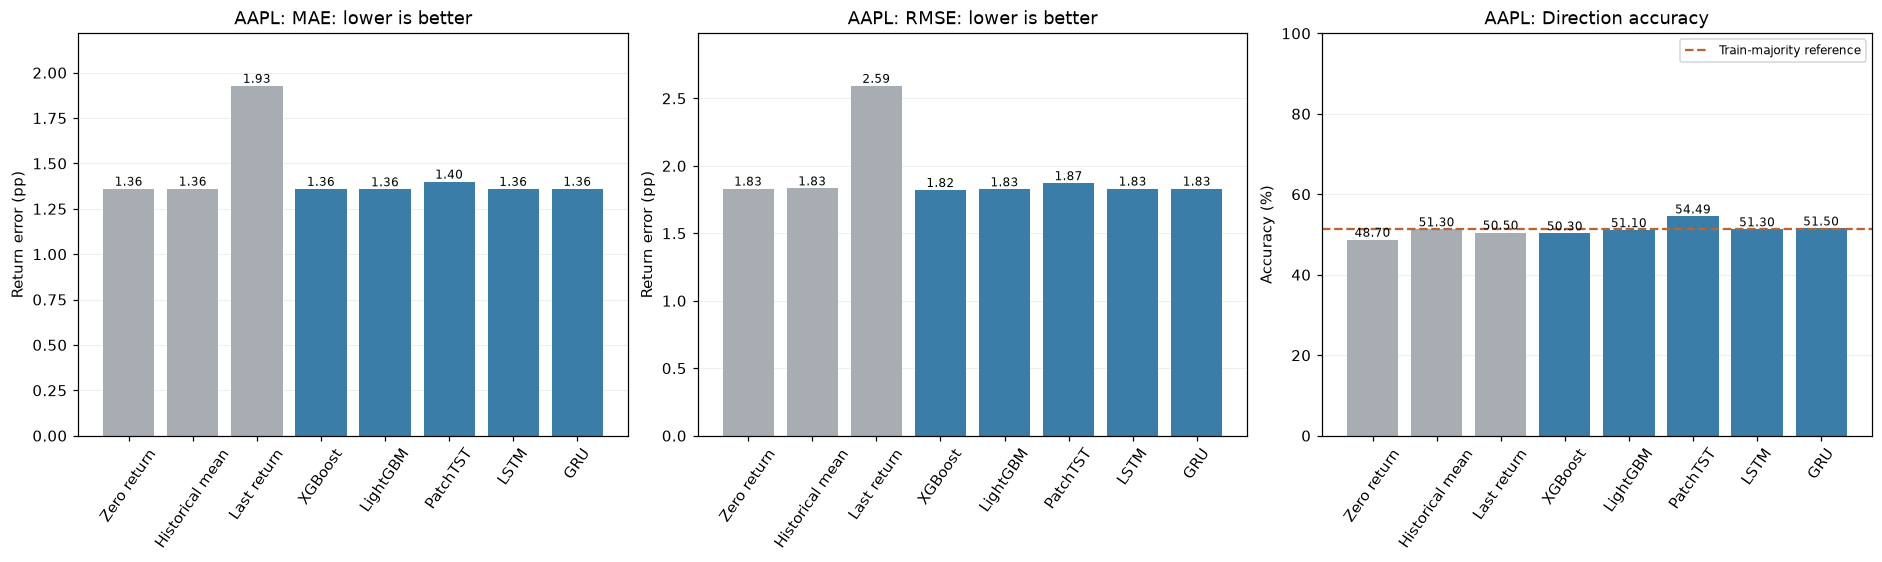

In [5]:
summary = pd.DataFrame(metrics).T
regression = summary[["n", "mae", "rmse", "r2", "r2_vs_zero"]].astype(float).copy()
regression["n"] = regression["n"].astype(int)
regression[["mae", "rmse"]] *= 100
regression = regression.rename(index=LABELS, columns={"n": "N", "mae": "MAE (pp)",
                           "rmse": "RMSE (pp)", "r2": "R2", "r2_vs_zero": "R2 vs zero"})
display(regression.sort_values("RMSE (pp)").round(6))
direction = summary[["direction_accuracy", "up_precision", "up_recall", "up_f1",
                     "actual_up_rate", "predicted_up_rate"]].astype(float).rename(index=LABELS)
display(direction.style.format("{:.2%}"))
print("Train-majority validation accuracy:", f"{reference['validation_accuracy']:.2%}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
colors = ["#a8adb3" if n in BASELINES else "#397da8" for n in names]
for ax, metric, title, ylabel in zip(axes, ("mae", "rmse", "direction_accuracy"),
        ("MAE: lower is better", "RMSE: lower is better", "Direction accuracy"),
        ("Return error (pp)", "Return error (pp)", "Accuracy (%)")):
    values = summary.loc[names, metric].astype(float).to_numpy() * 100
    bars = ax.bar([LABELS[n] for n in names], values, color=colors)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
    ax.set(title=f"{ticker}: {title}", ylabel=ylabel)
    ax.tick_params(axis="x", rotation=55)
    ax.grid(axis="y", alpha=0.2); ax.set_axisbelow(True)
    ax.margins(y=0.15)
axes[2].axhline(reference["validation_accuracy"] * 100, color="#b76533", linestyle="--",
               label="Train-majority reference")
axes[2].set_ylim(0, 100); axes[2].legend(fontsize=8)
plt.show()

## 4. 五模型逐日预测与累计平方误差

左图为整个验证期，右图为最近 `RECENT_DAYS` 个目标日。所有模型使用相同纵轴范围方便比较。累计平方误差曲线越低越好，**不是累计收益或交易回测**。

,target_date,actual_return,xgboost,lightgbm,patchtst,lstm,gru
0,2022-01-03,0.025004,0.001566,0.001131,-0.003365,0.000733,0.000727
1,2022-01-04,-0.012692,0.000730,0.000716,-0.001214,0.000689,0.000550
2,2022-01-05,-0.026600,0.001752,0.001976,-0.002894,0.000750,0.000778
3,2022-01-06,-0.016693,-0.000422,0.000916,-0.003140,0.000943,0.001486
4,2022-01-07,0.000988,0.000110,-0.000385,0.008447,0.001020,0.001424
5,2022-01-10,0.000116,0.000425,0.000567,0.004602,0.001035,0.001405
6,2022-01-11,0.016784,0.003521,0.002358,0.005136,0.000932,0.000664
7,2022-01-12,0.002570,-0.000956,0.000039,-0.001778,0.000817,0.000288


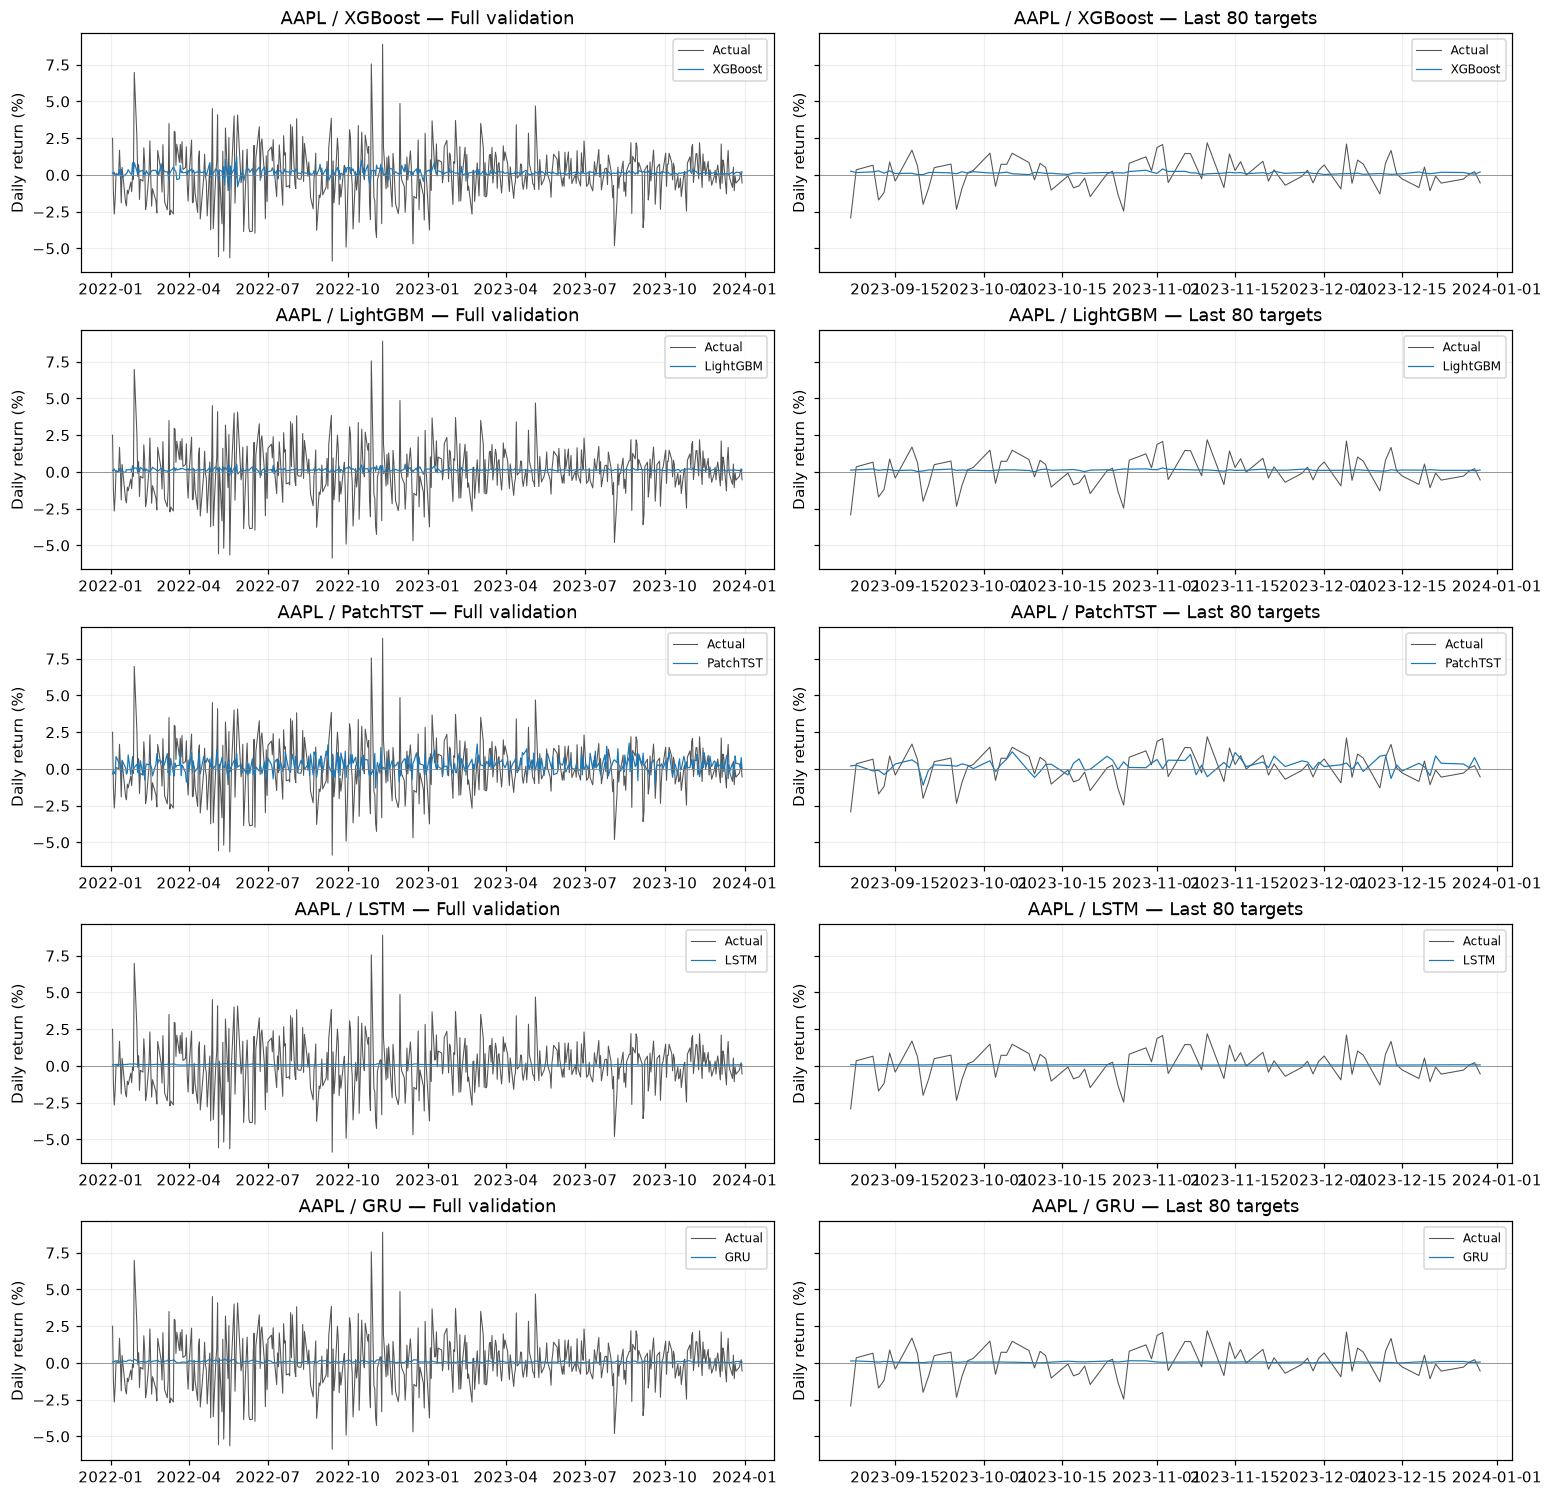

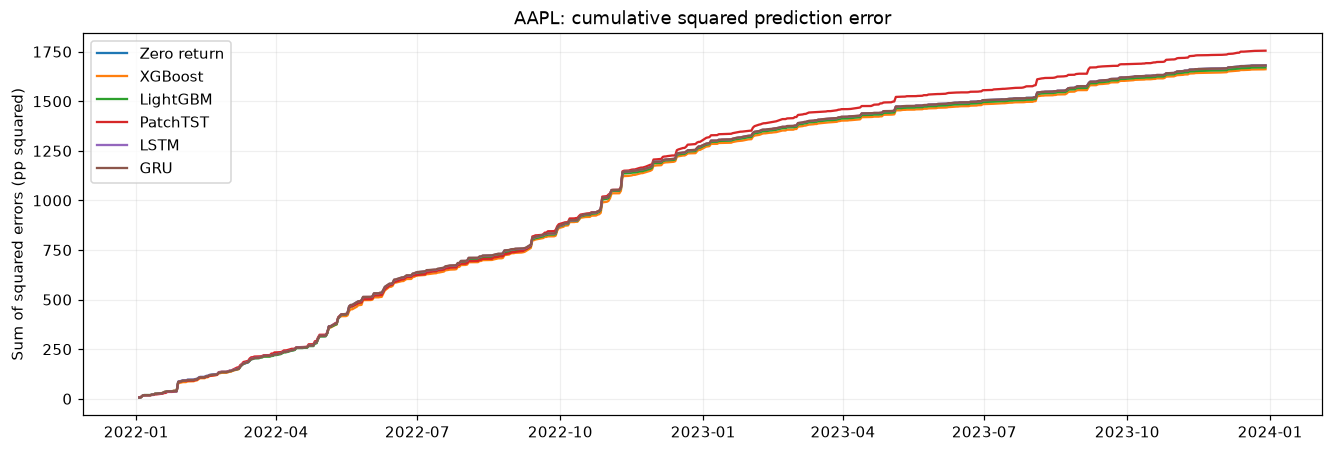

In [6]:
display(predictions[["target_date", "actual_return", *learned]].head(8))
if learned:
    fig, axes = plt.subplots(len(learned), 2, figsize=(14, 2.7 * len(learned)),
                             squeeze=False, sharey=True, layout="constrained")
    for row, name in enumerate(learned):
        for ax, frame, title in zip(axes[row], (predictions, predictions.tail(RECENT_DAYS)),
                                   ("Full validation", f"Last {RECENT_DAYS} targets")):
            ax.plot(frame.target_date, frame.actual_return * 100, label="Actual", linewidth=0.7, color="#555555")
            ax.plot(frame.target_date, frame[name] * 100, label=LABELS[name], linewidth=0.8)
            ax.axhline(0, color="grey", linewidth=0.5)
            ax.set(title=f"{ticker} / {LABELS[name]} — {title}", ylabel="Daily return (%)")
            ax.legend(fontsize=8); ax.grid(alpha=0.2)
    plt.show()
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
for name in ("zero_return", *learned):
    errors_pp = (predictions[name] - predictions.actual_return) * 100
    ax.plot(predictions.target_date, errors_pp.pow(2).cumsum(), label=LABELS[name])
ax.set(title=f"{ticker}: cumulative squared prediction error", ylabel="Sum of squared errors (pp squared)")
ax.legend(); ax.grid(alpha=0.2)
plt.show()

## 5. 训练过程与资源记录

将训练记录统一换算为收益 RMSE（百分点）：标准化 RMSE 乘以目标标准差；标准化 MSE 先开平方再换算。XGBoost 当前只记录验证曲线，不补造训练曲线。

XGBoost 保存的 `best_iteration` 从 0 开始，此处加 1 显示；LightGBM 的迭代数和神经网络的 epoch 从 1 开始。神经网络训练曲线是在训练过程中按批次累计的，和整轮结束后计算的验证值并非完全相同的测量方式。

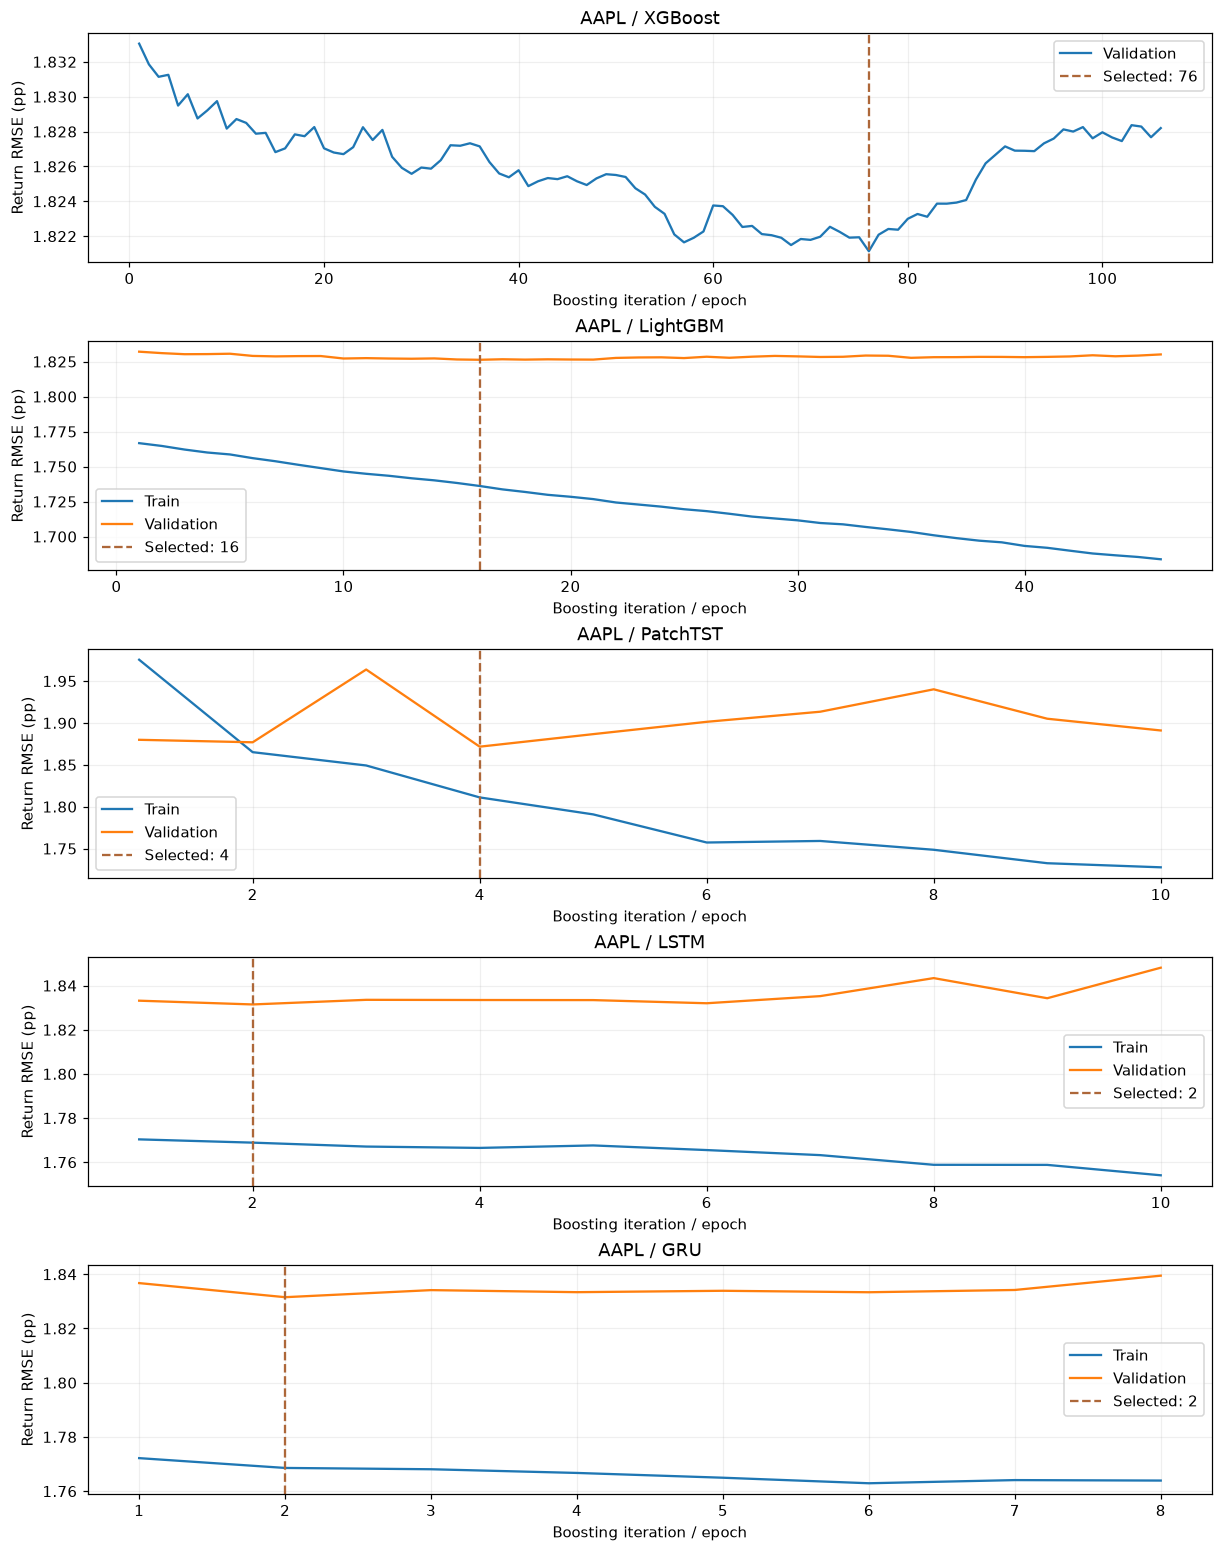

,Device,Seconds,Selected step (1-based),Steps evaluated
Model,,,,
XGBoost,cpu,0.849,76,106
LightGBM,cpu,0.194,16,46
PatchTST,cuda,12.286,4,10
LSTM,cuda,6.118,2,10
GRU,cuda,4.140,2,8


In [7]:
records = []
scale_pp = preprocessing["target_scale"] * 100
if learned:
    fig, axes = plt.subplots(len(learned), 1, figsize=(11, 2.8 * len(learned)),
                             squeeze=False, layout="constrained")
    for ax, name in zip(axes[:, 0], learned):
        info = training[name]
        hist = info["history"]
        if name == "xgboost":
            validation_rmse = np.asarray(hist["validation_0"]["rmse"]) * scale_pp
            train_rmse = None
            best = info["best_iteration"] + 1
        elif name == "lightgbm":
            validation_rmse = np.asarray(hist["validation"]["rmse"]) * scale_pp
            train_rmse = np.asarray(hist["train"]["rmse"]) * scale_pp
            best = info["best_iteration"]
        else:
            validation_rmse = np.sqrt([row["validation_mse_scaled"] for row in hist]) * scale_pp
            train_rmse = np.sqrt([row["train_mse_scaled"] for row in hist]) * scale_pp
            best = info["best_epoch"]
        steps = np.arange(1, len(validation_rmse) + 1)
        if train_rmse is not None:
            ax.plot(steps, train_rmse, label="Train")
        ax.plot(steps, validation_rmse, label="Validation")
        ax.axvline(best, linestyle="--", color="#ad6739", label=f"Selected: {best}")
        ax.set(title=f"{ticker} / {LABELS[name]}", xlabel="Boosting iteration / epoch", ylabel="Return RMSE (pp)")
        ax.legend(); ax.grid(alpha=0.2)
        records.append({"Model": LABELS[name], "Device": info.get("device"),
                        "Seconds": info["seconds"], "Selected step (1-based)": best,
                        "Steps evaluated": len(validation_rmse)})
    plt.show()
    display(pd.DataFrame(records).set_index("Model").round(3))

## 6. 五模型方向混淆矩阵

行是真实方向，列是预测方向；每格同时显示数量及其占真实类别的比例。检查模型是否几乎总预测上涨，或只对某一类表现较好。

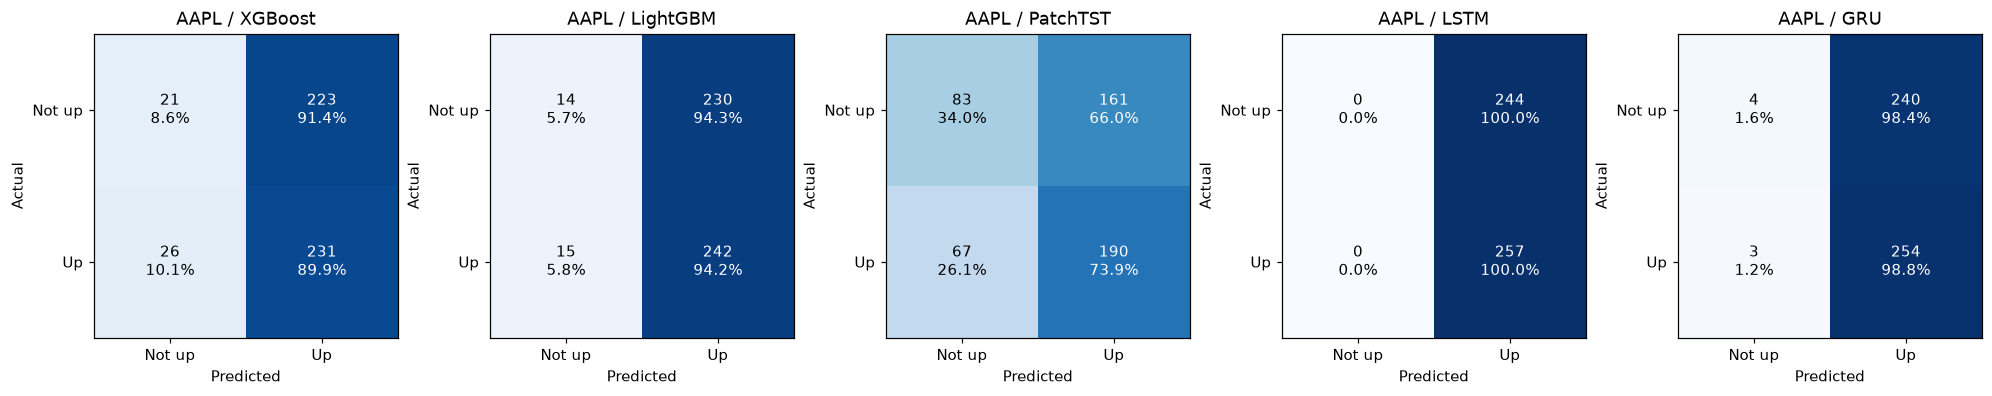

In [8]:
if learned:
    fig, axes = plt.subplots(1, len(learned), figsize=(3.6 * len(learned), 3.5),
                             squeeze=False, layout="constrained")
    for ax, name in zip(axes[0], learned):
        cm = np.asarray(metrics[name]["confusion_matrix"])
        counts = cm.sum(axis=1, keepdims=True)
        rates = np.divide(cm, counts, out=np.zeros_like(cm, dtype=float), where=counts != 0)
        ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
        for r in range(2):
            for c in range(2):
                ax.text(c, r, f"{cm[r, c]}\n{rates[r, c]:.1%}", ha="center", va="center",
                        color="white" if rates[r, c] > 0.6 else "black")
        ax.set(title=f"{ticker} / {LABELS[name]}", xticks=[0, 1], yticks=[0, 1],
               xticklabels=["Not up", "Up"], yticklabels=["Not up", "Up"],
               xlabel="Predicted", ylabel="Actual")
    plt.show()

## 7. 可选：树模型特征重要性

将 `SHOW_TREE_IMPORTANCE` 设为 `True` 可读取保存的树模型，将各滞后日的总分裂增益汇总到本次实验实际使用的特征（八个或六个）。不会重新训练。每个模型内部归一化后展示，两个模型的绝对增益不可直接比较；重要性也不是因果关系。

In [9]:
if SHOW_TREE_IMPORTANCE:
    shares = {}
    for name in (n for n in ("xgboost", "lightgbm") if n in learned):
        flat_gain = np.zeros(config["window"] * len(features))
        if name == "xgboost":
            from xgboost import Booster
            booster = Booster()
            booster.load_model(run_dir / "xgboost.ubj")
            for key, gain in booster.get_score(importance_type="total_gain").items():
                flat_gain[int(key[1:])] = gain
        else:
            from lightgbm import Booster
            booster = Booster(model_file=str(run_dir / "lightgbm.txt"))
            flat_gain = booster.feature_importance(importance_type="gain")
        gain = pd.Series(np.asarray(flat_gain).reshape(config["window"], len(features)).sum(axis=0),
                         index=features)
        shares[LABELS[name]] = gain / gain.sum() if gain.sum() else gain * 0
    if shares:
        importance = pd.DataFrame(shares)
        display(importance.style.format("{:.2%}"))
        ax = (importance * 100).plot.barh(figsize=(10, 5))
        ax.set(title=f"{ticker}: tree split-gain share across all lags", xlabel="Share within model (%)")
        plt.tight_layout(); plt.show()
else:
    print("Optional tree importance skipped. Set SHOW_TREE_IMPORTANCE = True to enable.")

Optional tree importance skipped. Set SHOW_TREE_IMPORTANCE = True to enable.


## 8. 本次结果摘要

下面的数值和排名来自所选实验，不预设哪个模型更好。单次验证集上的领先不能证明统计显著、跨时期稳定或可获利。最终测试集仍封存；后续多种子与滚动验证需小组共同确定。

In [10]:
if learned:
    best_rmse = min(learned, key=lambda n: metrics[n]["rmse"])
    best_direction = max(learned, key=lambda n: metrics[n]["direction_accuracy"])
    display(Markdown(
        f"**股票：{ticker}；所选实验：{run_dir.name}**，共 {len(predictions)} 个验证目标日。 "
        f"已选模型中 RMSE 最低的是 **{LABELS[best_rmse]}** "
        f"（{metrics[best_rmse]['rmse'] * 100:.4f} pp）；方向准确率最高的是 "
        f"**{LABELS[best_direction]}**（{metrics[best_direction]['direction_accuracy']:.2%}）。"
    ))
    for name in learned:
        m = metrics[name]
        comparison = "lower than" if m["rmse"] < metrics["zero_return"]["rmse"] else (
            "higher than" if m["rmse"] > metrics["zero_return"]["rmse"] else "equal to")
        print(f"{LABELS[name]}: validation RMSE {m['rmse']:.6f}, {comparison} the zero-return baseline; "
              f"direction accuracy {m['direction_accuracy']:.2%}; predicted up on {m['predicted_up_rate']:.2%} of days.")
    print("These are validation results. The final test set has not been evaluated in this experiment.")

**股票：AAPL；所选实验：aapl_compare_all_01**，共 501 个验证目标日。 已选模型中 RMSE 最低的是 **XGBoost** （1.8211 pp）；方向准确率最高的是 **PatchTST**（54.49%）。

XGBoost: validation RMSE 0.018211, lower than the zero-return baseline; direction accuracy 50.30%; predicted up on 90.62% of days.
LightGBM: validation RMSE 0.018263, lower than the zero-return baseline; direction accuracy 51.10%; predicted up on 94.21% of days.
PatchTST: validation RMSE 0.018717, higher than the zero-return baseline; direction accuracy 54.49%; predicted up on 70.06% of days.
LSTM: validation RMSE 0.018315, higher than the zero-return baseline; direction accuracy 51.30%; predicted up on 100.00% of days.
GRU: validation RMSE 0.018315, higher than the zero-return baseline; direction accuracy 51.50%; predicted up on 98.60% of days.
These are validation results. The final test set has not been evaluated in this experiment.
